In [1]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


/tmp/ipykernel_2962735/3771485902.py:138: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
find

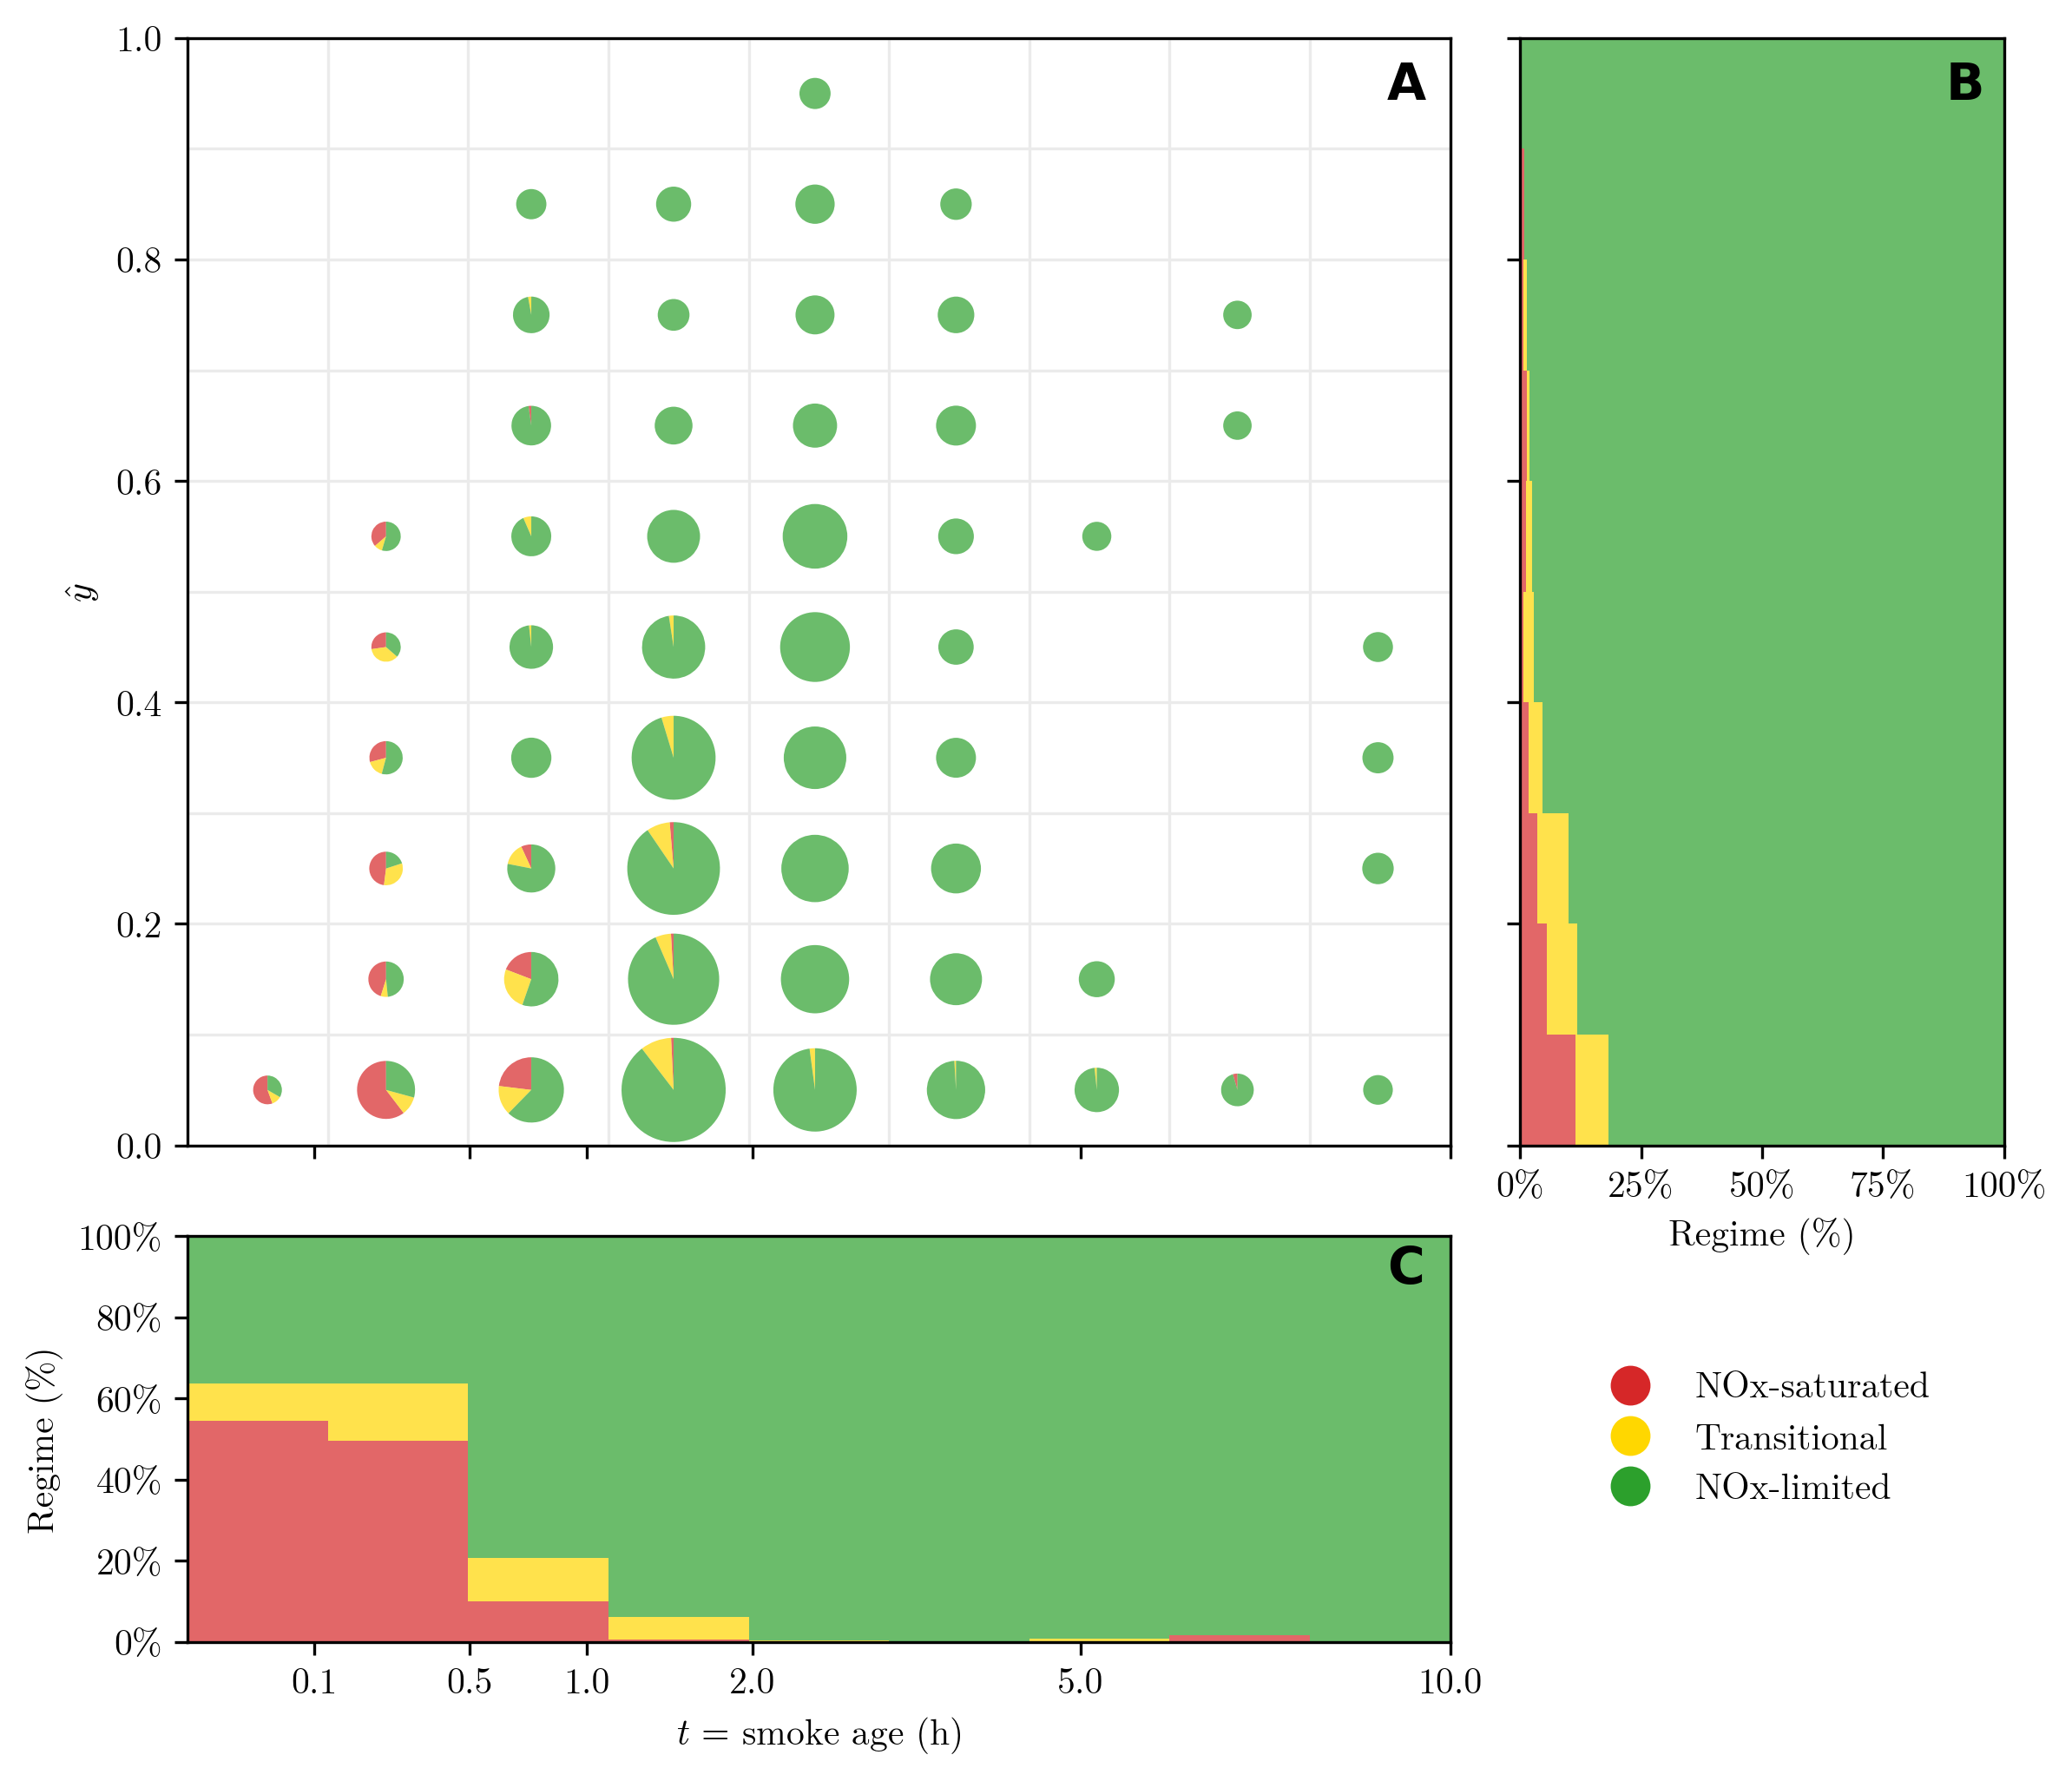

In [2]:
%matplotlib inline

import sys
from pathlib import Path

NB = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/notebooks")
if str(NB) not in sys.path:
    sys.path.insert(0, str(NB))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plume import AIRBORNE, ROOT, load_plume_table

from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.patches as mpatches

from plume import AGE_BINS_H, YHAT_BINS

df = load_plume_table()
tmp = df[
    np.isfinite(df["smoke_age"])
    & (df["smoke_age"] > 10)
    & (df["oh_phenol_benzene"] > 0)
    & (df["CO"] > 500)
    & df["normalized_distance_to_center"].notna()
    & df["regime"].notna()
].copy()

order = ["nox_saturated", "transitional", "nox_limited"]
labels = ["NOx-saturated", "Transitional", "NOx-limited"]
colors = {
    "nox_saturated": "tab:red",
    "transitional": "gold",
    "nox_limited": "tab:green",
}

ix = np.digitize(tmp["age_hr"], AGE_BINS_H) - 1
iy = np.digitize(tmp["normalized_distance_to_center"], YHAT_BINS) - 1
valid = (ix >= 0) & (ix < len(AGE_BINS_H) - 1) & (iy >= 0) & (iy < len(YHAT_BINS) - 1)
tmp = tmp.loc[valid].copy()
tmp["ix"] = ix[valid]
tmp["iy"] = iy[valid]

counts = (
    tmp.groupby(["ix", "iy", "regime"]).size()
    .unstack("regime", fill_value=0)
    .reindex(columns=order, fill_value=0)
)
totals = counts.sum(axis=1)
fractions = counts.divide(totals, axis=0).fillna(0.0)
keep = totals >= 8
x_centers = np.sqrt(AGE_BINS_H[:-1] * AGE_BINS_H[1:])
y_centers = 0.5 * (YHAT_BINS[:-1] + YHAT_BINS[1:])

tmp["age_bin"] = pd.cut(tmp["age_hr"], bins=AGE_BINS_H, include_lowest=True, right=False)
tmp["y_bin"] = pd.cut(tmp["normalized_distance_to_center"], bins=YHAT_BINS, include_lowest=True, right=False)
frac_age = tmp.groupby(["age_bin", "regime"], observed=False).size().unstack(fill_value=0)
frac_age = frac_age.reindex(columns=order, fill_value=0)
frac_age = frac_age.div(frac_age.sum(axis=1), axis=0) * 100
frac_y = tmp.groupby(["y_bin", "regime"], observed=False).size().unstack(fill_value=0)
frac_y = frac_y.reindex(columns=order, fill_value=0)
frac_y = frac_y.div(frac_y.sum(axis=1), axis=0) * 100

fig = plt.figure(figsize=(9, 8), dpi=300)
gs = fig.add_gridspec(2, 2, width_ratios=[3, 1.15], height_ratios=[3, 1.1], wspace=0.08, hspace=0.12)
ax_map = fig.add_subplot(gs[0, 0])
ax_side = fig.add_subplot(gs[0, 1], sharey=ax_map)
ax_bot = fig.add_subplot(gs[1, 0], sharex=ax_map)
ax_leg = fig.add_subplot(gs[1, 1])
ax_leg.axis("off")

for edge in AGE_BINS_H[1:]:
    ax_map.axvline(edge, color="0.92", lw=0.8, zorder=0)
for edge in YHAT_BINS:
    ax_map.axhline(edge, color="0.92", lw=0.8, zorder=0)

max_count = float(totals.max())
base_pt = 15
for (i, j), fracs in fractions[keep].iterrows():
    xc = 0.04 if i == 0 else x_centers[i]
    yc = y_centers[j]
    n = float(totals.loc[(i, j)])
    scale = n / max_count
    size_in = (base_pt * (0.5 + 1.5 * scale)) / 60.0
    inset = inset_axes(
        ax_map, width=size_in, height=size_in, loc="center",
        bbox_to_anchor=(xc, yc), bbox_transform=ax_map.transData, borderpad=0,
    )
    inset.pie(fracs.reindex(order).values, colors=[colors[r] for r in order], startangle=90, wedgeprops={"alpha": 0.7})
    inset.set(aspect="equal")
    inset.axis("off")

# ax_map.set_xlim(AGE_BINS_H[1], AGE_BINS_H[-1])
ax_map.set_xlim(0, 10)
ax_map.set_xscale("function", functions=(np.sqrt, np.square))
ax_map.set_xticks([0.1, 0.5, 1, 2, 5, 10])
ax_map.set_ylim(YHAT_BINS[0], YHAT_BINS[-1])
ax_map.set_ylabel(r"$\hat{y}$")
plt.setp(ax_map.get_xticklabels(), visible=False)

age_left = np.array([iv.left for iv in frac_age.index])
age_width = np.array([iv.right - iv.left for iv in frac_age.index])
bottom = np.zeros(len(frac_age))
for regime in order:
    vals = frac_age[regime].to_numpy()
    ax_bot.bar(age_left, vals, bottom=bottom, width=age_width, align="edge", color=colors[regime], alpha=0.7)
    bottom += vals
ax_bot.set_ylim(0, 100)
ax_bot.yaxis.set_major_formatter(PercentFormatter())
ax_bot.set_ylabel("Regime (%)")
ax_bot.set_xlabel(r"$t$ = smoke age (h)")

y_bottom = np.array([iv.left for iv in frac_y.index])
y_height = np.array([iv.right - iv.left for iv in frac_y.index])
left = np.zeros(len(frac_y))
for regime in order:
    vals = frac_y[regime].to_numpy()
    ax_side.barh(y_bottom, vals, left=left, height=y_height, align="edge", color=colors[regime], alpha=0.7)
    left += vals
ax_side.set_xlim(0, 100)
ax_side.xaxis.set_major_formatter(PercentFormatter())
ax_side.set_xlabel("Regime (%)")
plt.setp(ax_side.get_yticklabels(), visible=False)

handles = [
    plt.Line2D([0], [0], marker="o", linestyle="", color=colors[r], label=lab, markersize=10)
    for r, lab in zip(order, labels)
]
ax_leg.legend(handles=handles, loc="center", frameon=False)

for letter, axis, x in (("A", ax_map, 0.95), ("B", ax_side, 0.88), ("C", ax_bot, 0.95)):
    axis.text(x, 0.98, letter, transform=axis.transAxes, ha="left", va="top", fontsize=14, fontweight="bold", fontfamily="Arial")

fig.tight_layout()
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/fig03.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/fig03.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
